### Connect Workflow with LLM

In [3]:
%pip install langchain

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)

  Attempting uninstall: idna

    Found existing installation: idna 3.11

    Uninstalling idna-3.11:

      Successfully uninstalled idna-3.11

  Attempting uninstall: certifi

   ------------- -------------------------- 1/3 [certifi]
    Found existing installation: certifi 2025.11.12
   ------------- -------------------------- 1/3 [certifi]
    Uninstalling certifi-2025.11.12:
   ------------- -------------------------- 1/3 [certifi]
      Successfully uninstalled certifi-2025.11.12
   ------------- -------------------------- 1/3 [certifi]
   -------------------------- ------------- 2/3 [langchain]
   ---------------------------------------- 3/3 [langchain]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [14]:
%pip install langchain-google-genai


  Using cached langchain_google_genai-4.4.3-py3-none-any.whl.metadata (2.7 kB)
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached google_genai-3.0.0-py3-none-any.whl.metadata (60 kB)
  Using cached google_auth-2.62.1-py3-none-any.whl.metadata (6.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached langchain_google_genai-4.4.3-py3-none-any.whl (82 kB)
Using cached filetype-1.2.0-py2.py3-none-any.whl (19 kB)
Using cached google_genai-3.0.0-py3-none-any.whl (1.3 MB)
Using cached google_auth-2.62.1-py3-none-any.whl (267 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.3 MB 1.1 MB/s eta 0:00:02
   ------------------ --------------------- 1.0/2.3 MB 1.2 MB/s eta 0:00:01
   ----------------------- --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.


In [1]:
from dotenv import load_dotenv
from typing import TypedDict

from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END

d:\innomatics\venv\Lib\site-packages\langchain_core\utils\pydantic.py:42: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


In [2]:
# 1. API Key

load_dotenv()



True

In [3]:
# 2. Create LLM / model

model = init_chat_model(
     "gemini-3.5-flash",
    model_provider="google_genai"
)

In [4]:
# 3. Define State
class State(TypedDict):
    message: str
    response: str

In [5]:
# 4. Create Node
def chatbot(state):
    
    response = model.invoke(state["message"])
    
    return {
        "message": state["message"],
        "response": response.content
    }

In [6]:
# 5. Create Graph
builder = StateGraph(State)

In [7]:
# 6. Add Node
builder.add_node("chatbot", chatbot)


In [8]:
# 7. Add Edges
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

In [9]:

# 8. Compile
graph = builder.compile()

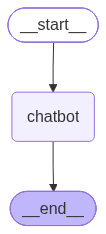

In [10]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())

In [11]:
# 9. Run
result = graph.invoke({
    "message": "What is deep learning?",
    "response": ""
})


In [12]:


# 10. Print response
print(result["response"])


[{'type': 'text', 'text': '**Deep learning** is a subfield of Artificial Intelligence (AI) and Machine Learning (ML) that teaches computers to process data in a way inspired by the human brain. \n\nIt is the technology behind many of today’s most advanced AI applications, including voice assistants (like Siri and Alexa), self-driving cars, facial recognition, and generative AI models (like ChatGPT).\n\nHere is a breakdown of how it works, how it differs from traditional machine learning, and why it is so powerful.\n\n---\n\n### 1. Where Deep Learning Fits (The Hierarchy)\nTo understand deep learning, it helps to see where it fits in the broader tech landscape:\n* **Artificial Intelligence (AI):** The overarching goal of making machines smart.\n* **Machine Learning (ML):** A subset of AI where computers learn patterns from data instead of being explicitly programmed.\n* **Deep Learning (DL):** A specialized, highly powerful subset of ML that uses multi-layered "neural networks" to learn